# Customer Churn Prediction

## Phase 4: Model Training

### Objectives
- Load preprocessed data
- Train Logistic Regression
- Make predictions
- Evaluate classification performance
- Understand classification metrics

# Import Libraries 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Load Preprocessed Data

In [2]:
data = joblib.load("../data/processed/processed_data.pkl")

X_train = data["X_train"]
X_val = data["X_val"]
X_test = data["X_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (4929, 50)
Validation: (1057, 50)
Test: (1057, 50)


### Convert target into numeric

In [3]:
y_train = y_train.map({"No": 0, "Yes": 1})
y_val = y_val.map({"No": 0, "Yes": 1})
y_test = y_test.map({"No": 0, "Yes": 1})

print(y_train.value_counts())

Churn
0    3621
1    1308
Name: count, dtype: int64


### Create a Baseline Model

In [4]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_val)

In [5]:
print("Baseline Accuracy:",
      accuracy_score(y_val, dummy_predictions))

print("Baseline Precision:",
      precision_score(y_val, dummy_predictions, zero_division=0))

print("Baseline Recall:",
      recall_score(y_val, dummy_predictions, zero_division=0))

print("Baseline F1:",
      f1_score(y_val, dummy_predictions, zero_division=0))

Baseline Accuracy: 0.7341532639545885
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1: 0.0


# Train Logistic Regression

In [6]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


# Make Predictions

In [7]:
# Predict class labels
y_val_pred = logistic_model.predict(X_val)

# Predict churn probabilities
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]

In [8]:
print("Accuracy:",
      accuracy_score(y_val, y_val_pred))

print("Precision:",
      precision_score(y_val, y_val_pred))

print("Recall:",
      recall_score(y_val, y_val_pred))

print("F1 Score:",
      f1_score(y_val, y_val_pred))

print("ROC-AUC:",
      roc_auc_score(y_val, y_val_proba))

print("PR-AUC (Average Precision):",
      average_precision_score(y_val, y_val_proba))

Accuracy: 0.7483443708609272
Precision: 0.5177304964539007
Recall: 0.7793594306049823
F1 Score: 0.6221590909090909
ROC-AUC: 0.8328411050372382
PR-AUC (Average Precision): 0.6392715936551433


# Confusion Matrix

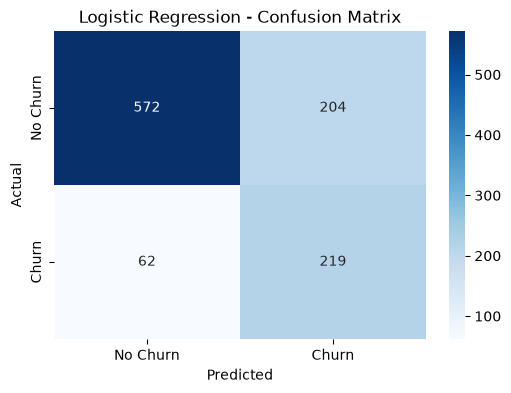

In [9]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

# Classification Report

In [10]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.81       776
       Churn       0.52      0.78      0.62       281

    accuracy                           0.75      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.75      0.76      1057



# Train Decision Tree

In [11]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

decision_tree.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [12]:
dt_pred = decision_tree.predict(X_val)
dt_proba = decision_tree.predict_proba(X_val)[:, 1]

# Train Random Forest

In [13]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [14]:
rf_pred = random_forest.predict(X_val)
rf_proba = random_forest.predict_proba(X_val)[:, 1]

# Train XGBoost

In [15]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [16]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [17]:
xgb_pred = xgb_model.predict(X_val)
xgb_proba = xgb_model.predict_proba(X_val)[:, 1]

# Train K-Nearest Neighbors (KNN)

In [18]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="minkowski"
)

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_val)
knn_proba = knn_model.predict_proba(X_val)[:, 1]

print("KNN training completed!")

KNN training completed!


# Train Support Vector Machine (SVM)

In [19]:
from sklearn.svm import SVC

svm_model = SVC(
    C=1.0,
    kernel="rbf",
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_val)
svm_proba = svm_model.predict_proba(X_val)[:, 1]

print("SVM training completed!")

/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!


# Train Naive Bayes

In [20]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_val)
nb_proba = nb_model.predict_proba(X_val)[:, 1]

print("Naive Bayes training completed!")

Naive Bayes training completed!


# Train Gradient Boosting

In [21]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_val)
gb_proba = gb_model.predict_proba(X_val)[:, 1]

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


# Model Evaluation Function

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(name, y_true, y_pred, y_proba):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC (AP)": average_precision_score(y_true, y_proba)
    }

# Compare All Models

In [23]:
results = []

# Logistic Regression
results.append(
    evaluate_model(
        "Logistic Regression",
        y_val,
        y_val_pred,
        y_val_proba
    )
)

# Decision Tree
results.append(
    evaluate_model(
        "Decision Tree",
        y_val,
        dt_pred,
        dt_proba
    )
)

# Random Forest
results.append(
    evaluate_model(
        "Random Forest",
        y_val,
        rf_pred,
        rf_proba
    )
)

# XGBoost
results.append(
    evaluate_model(
        "XGBoost",
        y_val,
        xgb_pred,
        xgb_proba
    )
)

# K-Nearest Neighbors (KNN)
results.append(
    evaluate_model(
        "KNN",
        y_val,
        knn_pred,
        knn_proba
    )
)
# Support Vector Machine (SVM)
results.append(
    evaluate_model(
        "SVM",
        y_val,
        svm_pred,
        svm_proba
    )
)

# Naive Bayes
results.append(
    evaluate_model(
        "Naive Bayes",
        y_val,
        nb_pred,
        nb_proba
    )
)

# Gradient Boosting
results.append(
    evaluate_model(
        "Gradient Boosting",
        y_val,
        gb_pred,
        gb_proba
    )
)


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC (AP)",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (AP)
3,XGBoost,0.751183,0.521429,0.779359,0.624822,0.837606,0.642633
7,Gradient Boosting,0.798486,0.666667,0.483986,0.560825,0.837943,0.640355
2,Random Forest,0.761589,0.536341,0.761566,0.629412,0.834740,0.639461
0,Logistic Regression,0.748344,0.517730,0.779359,0.622159,0.832841,0.639272
5,SVM,0.742668,0.510791,0.758007,0.610315,0.812566,0.606227
6,Naive Bayes,0.688742,0.452000,0.804270,0.578745,0.801730,0.580397
1,Decision Tree,0.740776,0.508557,0.740214,0.602899,0.814201,0.577907
4,KNN,0.759697,0.555102,0.483986,0.517110,0.757620,0.519537


# Visualize Model Comparison

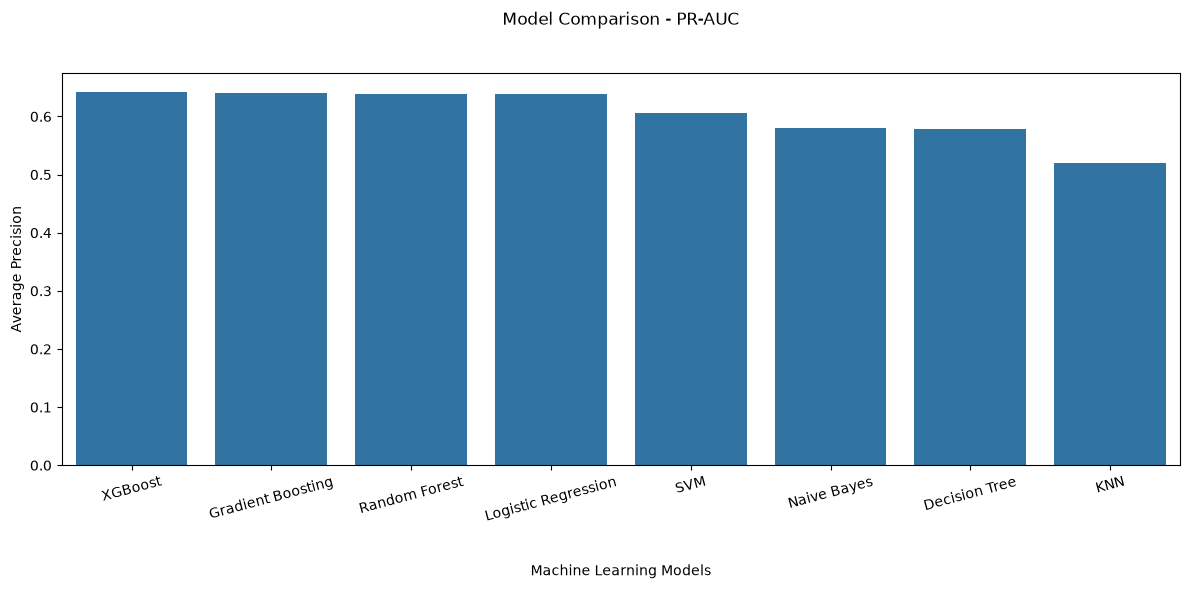

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="PR-AUC (AP)"
)

plt.title("Model Comparison - PR-AUC\n\n")
plt.xlabel("\n\nMachine Learning Models")
plt.ylabel("Average Precision")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Cross-Validation Libraries

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
from sklearn.pipeline import Pipeline

In [40]:
data = joblib.load("../data/processed/processed_data.pkl")

X_train_raw = data["X_train_raw"]
y_train = data["y_train"].map({"No": 0, "Yes": 1})


X_val_raw = data["X_val_raw"]
X_test_raw = data["X_test_raw"]

# Create Cross-Validation Strategy

In [41]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [42]:
# Load fitted preprocessor
preprocessor = joblib.load("../models/preprocessor.pkl")

print("Preprocessor loaded successfully!")

Preprocessor loaded successfully!


In [43]:
print("Raw Training Shape:", X_train_raw.shape)
print("Target Shape:", y_train.shape)

print(X_train_raw.head())

Raw Training Shape: (4929, 21)
Target Shape: (4929,)
      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
4926    Male              0     Yes         No      62          Yes   
6392  Female              0     Yes        Yes      60           No   
6890    Male              0      No         No      53          Yes   
3194  Female              1     Yes         No      43           No   
2599  Female              0      No         No      72          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  ...  \
4926                No             DSL             No          Yes  ...   
6392  No phone service             DSL             No          Yes  ...   
6890                No             DSL             No           No  ...   
3194  No phone service             DSL             No          Yes  ...   
2599                No             DSL            Yes          Yes  ...   

     TechSupport StreamingTV StreamingMovies        Contract Paperles

# Create Preprocessing Pipeline

In [44]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

def create_pipeline(model):

    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(model))
    ])

In [45]:
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "SVM": svm_model,
    "Naive Bayes": nb_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

cv_results = []

for name, model in models.items():

    print(f"Training {name}...")

    pipeline = create_pipeline(model)

    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
        "PR-AUC_STD": scores["test_pr_auc"].std()
    })

print("All 8 models cross-validation completed!")

Training Logistic Regression...
Training KNN...
Training Decision Tree...
Training Random Forest...
Training SVM...


/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. 

Training Naive Bayes...
Training Gradient Boosting...
Training XGBoost...
All 8 models cross-validation completed!


# Compare Results

In [47]:
cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

cv_results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,PR-AUC_STD
0,XGBoost,0.750456,0.519892,0.781334,0.624187,0.845853,0.670005,0.025687
1,Gradient Boosting,0.805436,0.671156,0.528303,0.590544,0.846226,0.669474,0.025217
2,Logistic Regression,0.748226,0.516734,0.792829,0.625447,0.846688,0.664480,0.021594
3,Random Forest,0.764051,0.539183,0.771387,0.634281,0.845271,0.663762,0.023959
4,Naive Bayes,0.710491,0.474518,0.840967,0.606505,0.824908,0.630793,0.024607
5,Decision Tree,0.731992,0.497254,0.806587,0.615096,0.827431,0.613714,0.023076
6,SVM,0.745994,0.514136,0.784382,0.620898,0.824237,0.588131,0.021164
7,KNN,0.749851,0.530543,0.506905,0.518262,0.759127,0.526830,0.026408


# Visualize Cross-Validation Results

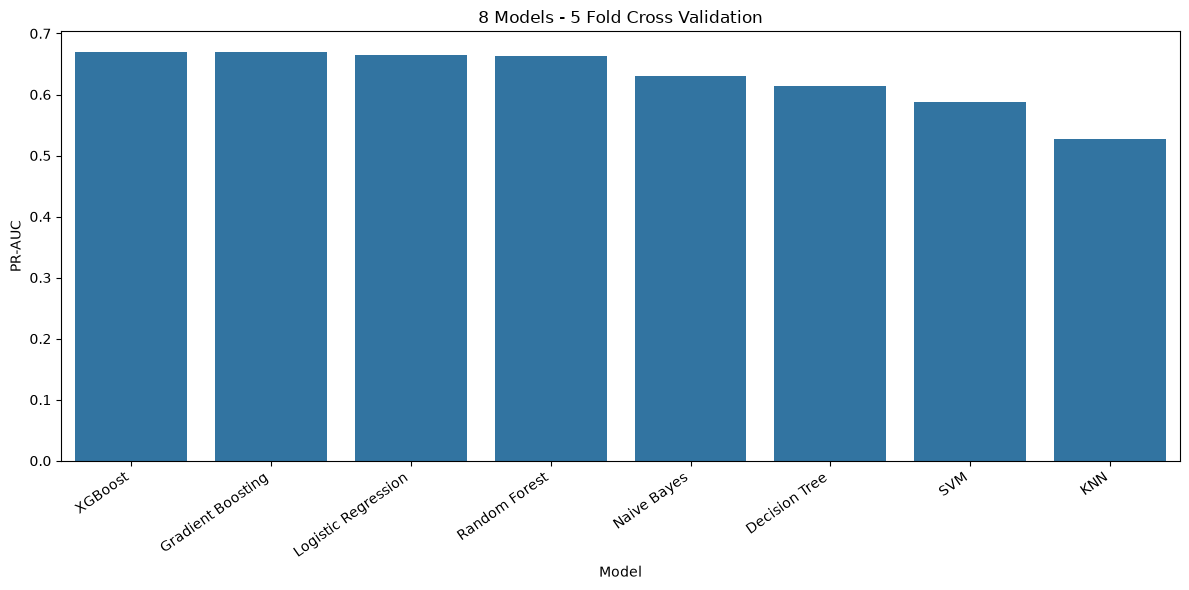

In [48]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="PR-AUC"
)

plt.title("8 Models - 5 Fold Cross Validation")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Hyperparameter Tuning

In [49]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
import pandas as pd

In [50]:
param_distributions = {
    "XGBoost": {
        "classifier__n_estimators": [100, 200, 300, 400],
        "classifier__max_depth": [2, 3, 4, 5],
        "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
        "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
    },

    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "classifier__max_depth": [2, 3, 4],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 3, 5],
        "classifier__subsample": [0.7, 0.8, 0.9, 1.0]
    },

    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 0.5, 1, 5, 10],
        "classifier__solver": ["lbfgs"],
        "classifier__max_iter": [1000, 2000]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300, 400],
        "classifier__max_depth": [5, 10, 15, 20, None],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4],
        "classifier__max_features": ["sqrt", "log2"]
    }
}

In [51]:
tuning_models = {
    "XGBoost": models["XGBoost"],
    "Gradient Boosting": models["Gradient Boosting"],
    "Logistic Regression": models["Logistic Regression"],
    "Random Forest": models["Random Forest"]
}

tuning_results = []
best_estimators = {}

for name, model in tuning_models.items():

    print(f"\nTuning {name}...")

    pipeline = create_pipeline(model)

    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions[name],
        n_iter=20,
        scoring="average_precision",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    random_search.fit(X_train_raw, y_train)

    best_estimators[name] = random_search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best PR-AUC": random_search.best_score_,
        "Best Parameters": random_search.best_params_
    })

    print("Best PR-AUC:", random_search.best_score_)
    print("Best Parameters:", random_search.best_params_)


Tuning XGBoost...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best PR-AUC: 0.6720569219963577
Best Parameters: {'classifier__subsample': 0.7, 'classifier__n_estimators': 400, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.7}

Tuning Gradient Boosting...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best PR-AUC: 0.6716946782140575
Best Parameters: {'classifier__subsample': 0.7, 'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.05}

Tuning Logistic Regression...
Fitting 5 folds for each of 12 candidates, totalling 60 fits


/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_search.py:326: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best PR-AUC: 0.6644800247739254
Best Parameters: {'classifier__solver': 'lbfgs', 'classifier__max_iter': 1000, 'classifier__C': 1}

Tuning Random Forest...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best PR-AUC: 0.6620568775335278
Best Parameters: {'classifier__n_estimators': 400, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2', 'classifier__max_depth': 10}


In [52]:
tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    by="Best PR-AUC",
    ascending=False
).reset_index(drop=True)

tuning_results_df

,Model,Best PR-AUC,Best Parameters
0,XGBoost,0.672057,"{'classifier__subsample': 0.7, 'classifier__n_..."
1,Gradient Boosting,0.671695,"{'classifier__subsample': 0.7, 'classifier__n_..."
2,Logistic Regression,0.664480,"{'classifier__solver': 'lbfgs', 'classifier__m..."
3,Random Forest,0.662057,"{'classifier__n_estimators': 400, 'classifier_..."


# Tuned Models Validation

In [55]:
validation_results = []

for name, model in best_estimators.items():

    y_val_pred = model.predict(X_val_raw)
    y_val_prob = model.predict_proba(X_val_raw)[:, 1]

    metrics = evaluate_model(
        name,
        y_val,
        y_val_pred,
        y_val_prob
    )

    validation_results.append(metrics)

In [57]:
validation_results_df = pd.DataFrame(validation_results)

validation_results_df = validation_results_df.sort_values(
    by="PR-AUC (AP)",
    ascending=False
).reset_index(drop=True)

validation_results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (AP)
0,Gradient Boosting,0.802271,0.680000,0.483986,0.565489,0.839009,0.645984
1,XGBoost,0.753075,0.523697,0.786477,0.628734,0.838126,0.644823
2,Random Forest,0.762535,0.537879,0.758007,0.629247,0.835038,0.639814
3,Logistic Regression,0.748344,0.517730,0.779359,0.622159,0.832841,0.639272


# threshold optimization

In [58]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

In [59]:
selected_models = {
    "XGBoost": best_estimators["XGBoost"],
    "Gradient Boosting": best_estimators["Gradient Boosting"]
}

In [60]:
threshold_results = []

for name, model in selected_models.items():

    y_val_prob = model.predict_proba(X_val_raw)[:, 1]

    precisions, recalls, thresholds = precision_recall_curve(
        y_val,
        y_val_prob
    )

    f1_scores = (
        2 * precisions[:-1] * recalls[:-1]
        / (precisions[:-1] + recalls[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_scores)

    threshold_results.append({
        "Model": name,
        "Best Threshold": thresholds[best_idx],
        "Best Precision": precisions[best_idx],
        "Best Recall": recalls[best_idx],
        "Best F1": f1_scores[best_idx]
    })

In [61]:
threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df

,Model,Best Threshold,Best Precision,Best Recall,Best F1
0,XGBoost,0.535933,0.547315,0.761566,0.636905
1,Gradient Boosting,0.327840,0.577143,0.718861,0.640254


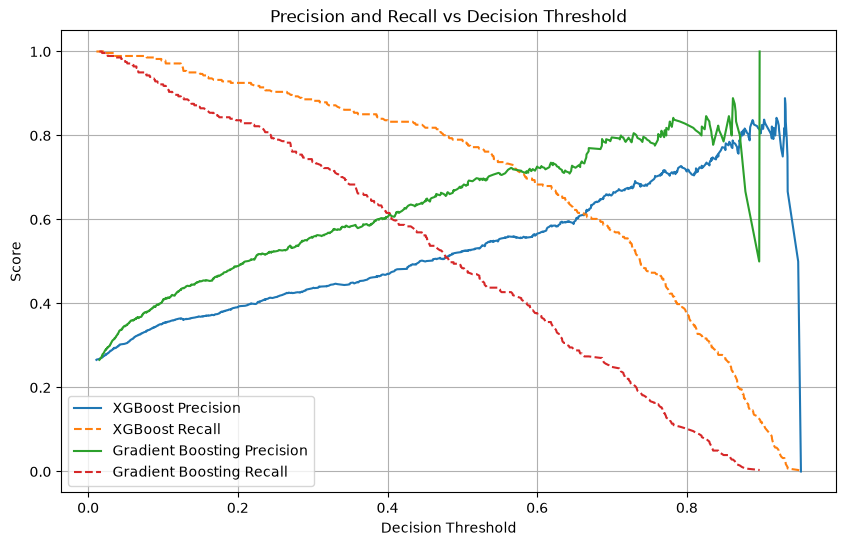

In [62]:
plt.figure(figsize=(10, 6))

for name, model in selected_models.items():

    y_val_prob = model.predict_proba(X_val_raw)[:, 1]

    precisions, recalls, thresholds = precision_recall_curve(
        y_val,
        y_val_prob
    )

    plt.plot(
        thresholds,
        precisions[:-1],
        label=f"{name} Precision"
    )

    plt.plot(
        thresholds,
        recalls[:-1],
        linestyle="--",
        label=f"{name} Recall"
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Decision Threshold")
plt.legend()
plt.grid()
plt.show()

# Confusion Matrix

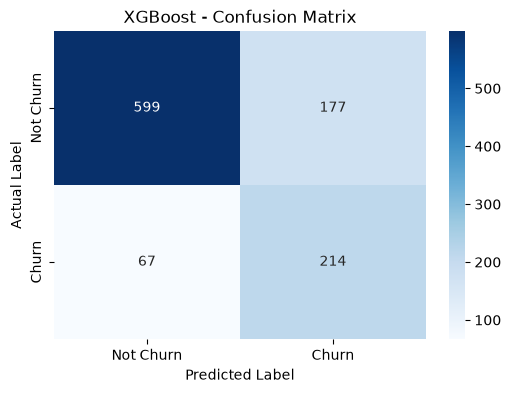


XGBoost - Threshold: 0.536
              precision    recall  f1-score   support

   Not Churn       0.90      0.77      0.83       776
       Churn       0.55      0.76      0.64       281

    accuracy                           0.77      1057
   macro avg       0.72      0.77      0.73      1057
weighted avg       0.81      0.77      0.78      1057



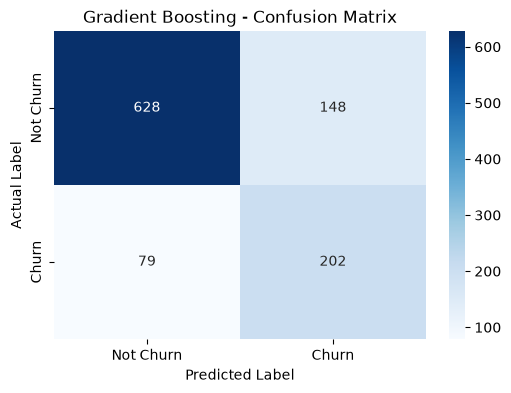


Gradient Boosting - Threshold: 0.328
              precision    recall  f1-score   support

   Not Churn       0.89      0.81      0.85       776
       Churn       0.58      0.72      0.64       281

    accuracy                           0.79      1057
   macro avg       0.73      0.76      0.74      1057
weighted avg       0.81      0.79      0.79      1057



In [63]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

for name, model in selected_models.items():

    best_threshold = threshold_results_df.loc[
        threshold_results_df["Model"] == name,
        "Best Threshold"
    ].iloc[0]

    y_val_prob = model.predict_proba(X_val_raw)[:, 1]

    y_val_pred = (y_val_prob >= best_threshold).astype(int)

    cm = confusion_matrix(y_val, y_val_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Churn", "Churn"],
        yticklabels=["Not Churn", "Churn"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.show()

    print(f"\n{name} - Threshold: {best_threshold:.3f}")
    print(classification_report(
        y_val,
        y_val_pred,
        target_names=["Not Churn", "Churn"],
        zero_division=0
    ))

# Final Test Evaluation

In [64]:
final_model = best_estimators["XGBoost"]

best_threshold = 0.536

y_test_prob = final_model.predict_proba(X_test_raw)[:, 1]

y_test_pred = (y_test_prob >= best_threshold).astype(int)

In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

print("Final Test Results")

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))
print("PR-AUC:", average_precision_score(y_test, y_test_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Not Churn", "Churn"]
))

Final Test Results
Accuracy: 0.759697256385998
Precision: 0.5315533980582524
Recall: 0.7821428571428571
F1 Score: 0.6329479768786127
ROC-AUC: 0.8551043390329105
PR-AUC: 0.6728788749292407

Classification Report:
              precision    recall  f1-score   support

   Not Churn       0.91      0.75      0.82       777
       Churn       0.53      0.78      0.63       280

    accuracy                           0.76      1057
   macro avg       0.72      0.77      0.73      1057
weighted avg       0.81      0.76      0.77      1057



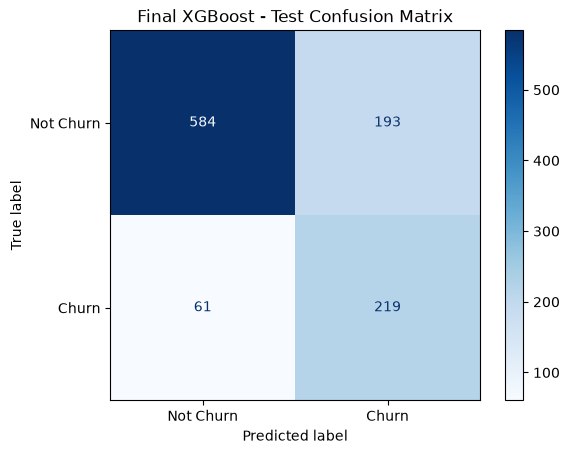

In [66]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title("Final XGBoost - Test Confusion Matrix")
plt.show()

# Save Final Model

In [67]:
import os

os.makedirs("../models", exist_ok=True)

In [68]:
import joblib

final_model = best_estimators["XGBoost"]

joblib.dump(
    final_model,
    "../models/customer_churn_xgboost.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [69]:
joblib.dump(
    0.536,
    "../models/decision_threshold.pkl"
)

print("Decision threshold saved successfully!")

Decision threshold saved successfully!


In [70]:
loaded_model = joblib.load(
    "../models/customer_churn_xgboost.pkl"
)

loaded_threshold = joblib.load(
    "../models/decision_threshold.pkl"
)

sample_predictions = loaded_model.predict_proba(
    X_test_raw.iloc[:5]
)[:, 1]

sample_predictions

array([0.12581491, 0.5177898 , 0.21529308, 0.7136694 , 0.7895283 ],
      dtype=float32)